# 1. What is thresholding?

Thresholding is an image-processing technique that compares pixel intensities against a threshold value to classify pixels into different groups.

A grayscale image typically has pixel values from `0` (black) to `255` (white).

For example, with a threshold \\(T=127\\):

- Pixels brighter than 127 become white.
- Pixels at or below 127 become black.



Why use it?

- Separate text from a document background.
- Prepare images for OCR.
- Extract object masks.
- Simplify images for contour detection.
- Segment foreground and background.

The four topics differ mainly in how the threshold is applied or selected.

## 2. Binary thresholding

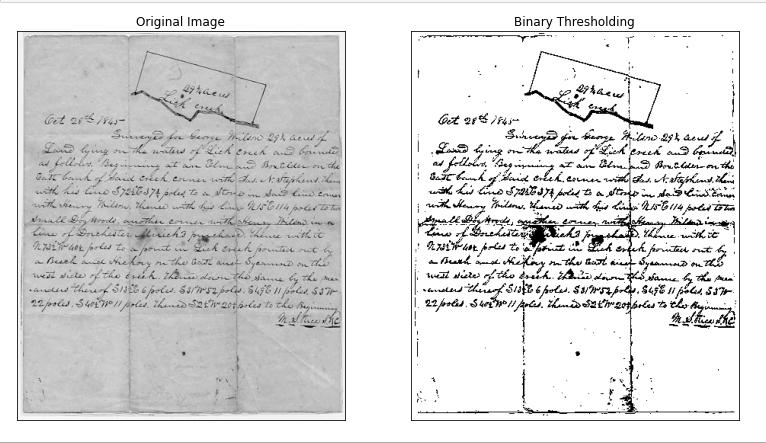

Binary thresholding applies one fixed threshold to every pixel. It is also called global thresholding.

### Formula

\\[ I'(x,y)= \begin{cases} 255 & I(x,y)>T\\\ 0 & I(x,y)\leq T \end{cases} \\]

Here, \\(T\\) is the threshold value.



Example: if the pixel value is 200, it becomes 255 (white). If it is 80, it becomes 0 (black).

The underscore `_` receives the threshold value returned by OpenCV, which we don't need in this example.

Best for: images with reasonably uniform lighting and clear foreground/background separation.

## 3. Inverse binary thresholding

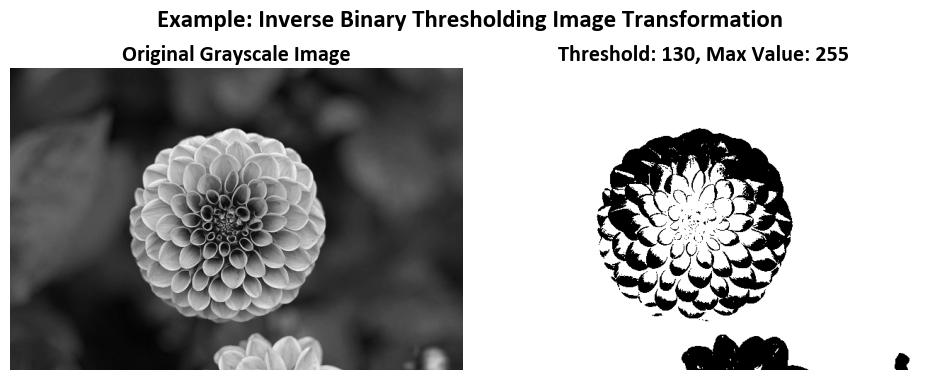]

Inverse thresholding reverses the binary output.

### Formula

\\[ I'(x,y)= \begin{cases} 0 & I(x,y)>T\\\ 255 & I(x,y)\leq T \end{cases} \\]

### Python code

```
_, binary_inv = cv2.threshold(    gray, 127, 255, cv2.THRESH_BINARY_INV)
```

For a threshold of 127:

| Input pixel | Binary      | Inverse binary |
| ----------- | ----------- | -------------- |
| 200         | 255 (white) | 0 (black)      |
| 80          | 0 (black)   | 255 (white)    |
| 127         | 0 (black)   | 255 (white)    |

When to use it: when you want the foreground or text to be white on a black background rather than black on white, or when a downstream algorithm expects the opposite polarity.

For example, ordinary dark text on a bright page often becomes white text on black with inverse thresholding.



## 4. Adaptive thresholding

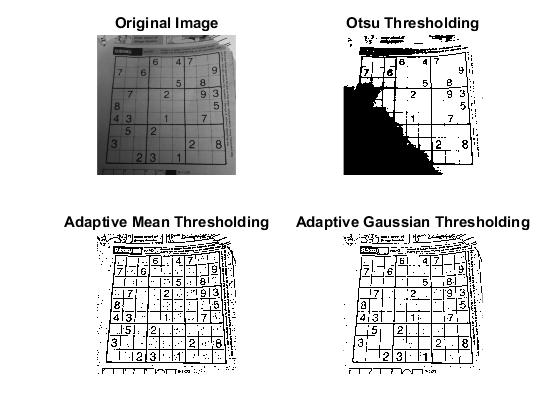

### Why do we need it?

Imagine photographing a document under uneven lighting: the left side is bright, but the right side is shadowed.

With binary thresholding, one global threshold might make the bright region look correct while losing text in the shadowed region.

Adaptive thresholding calculates a different threshold for each pixel using its local neighborhood. This makes it useful for unevenly illuminated documents.


### Two methods

A. Adaptive mean thresholding

Calculates the mean intensity of a local neighborhood and subtracts a constant \\(C\\).

\\[ T(x,y)=\operatorname{Mean}\_{\text{local}}-C \\]

B. Adaptive Gaussian thresholding

Calculates a Gaussian-weighted average of nearby pixels, giving more weight to pixels near the center.

\\[ T(x,y)=\operatorname{WeightedMean}\_{\text{local}}-C \\]

For both methods, pixels are compared against their own local threshold.



Best for: documents with shadows, uneven illumination, or varying local backgrounds.

## 5. Otsu's thresholding

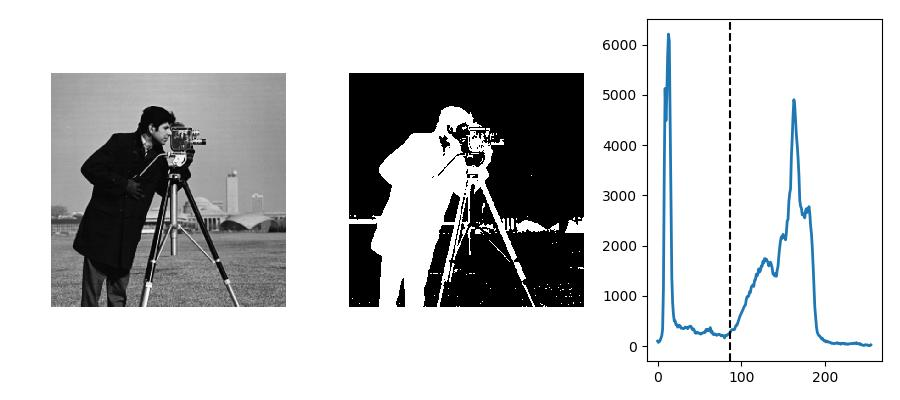

### The problem Otsu solves

In ordinary binary thresholding, you choose a value such as `127` yourself.

But what if `127` is not suitable for your image?

Otsu's method automatically selects a single global threshold from the image's intensity histogram. It is especially useful when the histogram separates into two reasonably distinct intensity groups, such as dark text and a bright background.



### Intuition

Imagine the histogram has two groups:

- Dark pixels: mostly between 0 and 80.
- Bright pixels: mostly between 180 and 255.

Otsu looks for a threshold that separates these groups well.

Mathematically, it selects the threshold that minimizes the weighted within-class variance:

\\[ \sigma_w^2(T)= w_0(T)\sigma_0^2(T)+ w_1(T)\sigma_1^2(T) \\]

Here, \\(w_0,w_1\\) are the proportions of pixels in the two classes, and \\(\sigma_0^2,\sigma_1^2\\) are their variances.





## 6. Compare all four methods

| Method         | How threshold is chosen                      | Best use                                 |
| -------------- | -------------------------------------------- | ---------------------------------------- |
| Binary         | One manually selected value                  | Uniform lighting                         |
| Inverse binary | One manually selected value, opposite output | Reversing foreground/background polarity |
| Adaptive       | Local neighborhood for each pixel            | Uneven lighting and shadows              |
| Otsu           | Automatically selected global value          | Clearly separable foreground/background  |

---

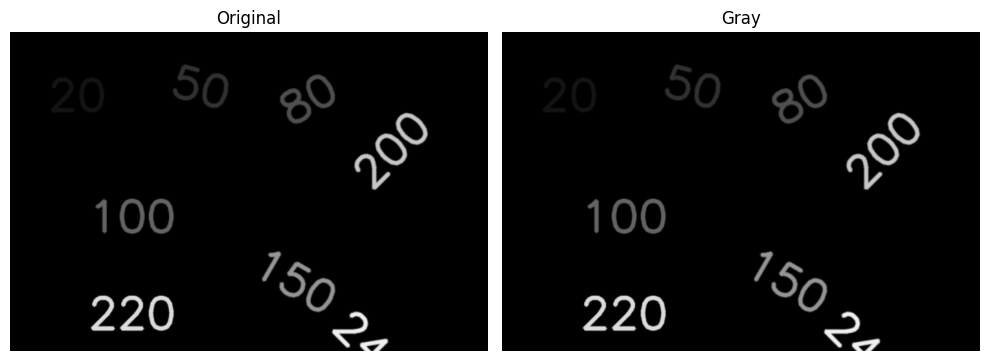

In [1]:
import cv2
import matplotlib.pyplot as plt 
import numpy as np 

image_path = 'images/04_image.png'

image = cv2.imread(image_path)
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)

gray = cv2.cvtColor(image,cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(image)
plt.title('Original')
plt.axis('off')

plt.subplot(1,2,2) 
plt.title('Gray')
plt.imshow(gray,cmap='gray',vmin=0,vmax=255)
plt.axis('off')

plt.tight_layout()
plt.show()

# Binary thresholding

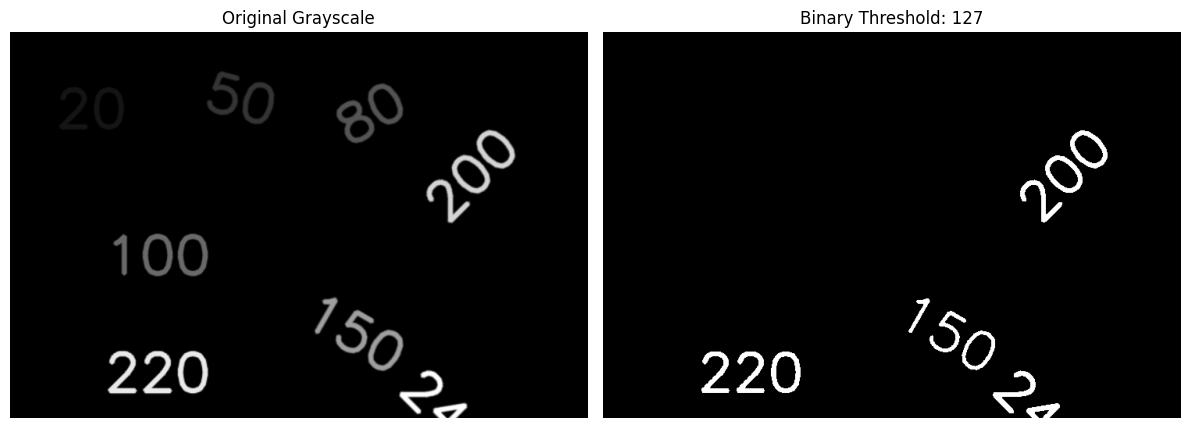

In [2]:
threshold_value = 127 

_,binary = cv2.threshold(
    gray,
    threshold_value,
    255,
    cv2.THRESH_BINARY
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binary Threshold: 127")
plt.axis("off")

plt.tight_layout()
plt.savefig('images/2_Thresholding/1.Binary_Treshold.jpg')
plt.show()

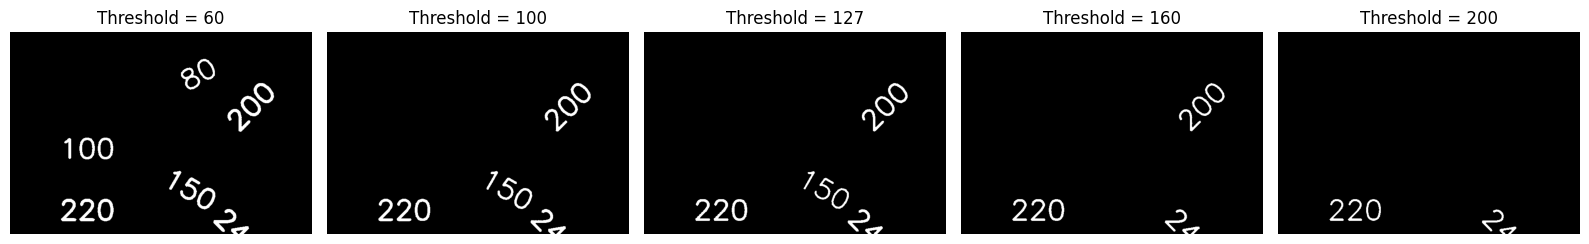

In [3]:
# Experiment with multiple thresholds

threshold_values = [60, 100, 127, 160, 200]

fig, axes = plt.subplots(1, len(threshold_values), figsize=(16, 4))

for ax, threshold_value in zip(axes, threshold_values):
    _, result = cv2.threshold(
        gray, threshold_value, 255, cv2.THRESH_BINARY
    )

    ax.imshow(result, cmap="gray")
    ax.set_title(f"Threshold = {threshold_value}")
    ax.axis("off")

plt.tight_layout()
plt.savefig('images/2_Thresholding/2.Binary_Treshold_diff_values.jpg')
plt.show()

# Inverse binary thresholding

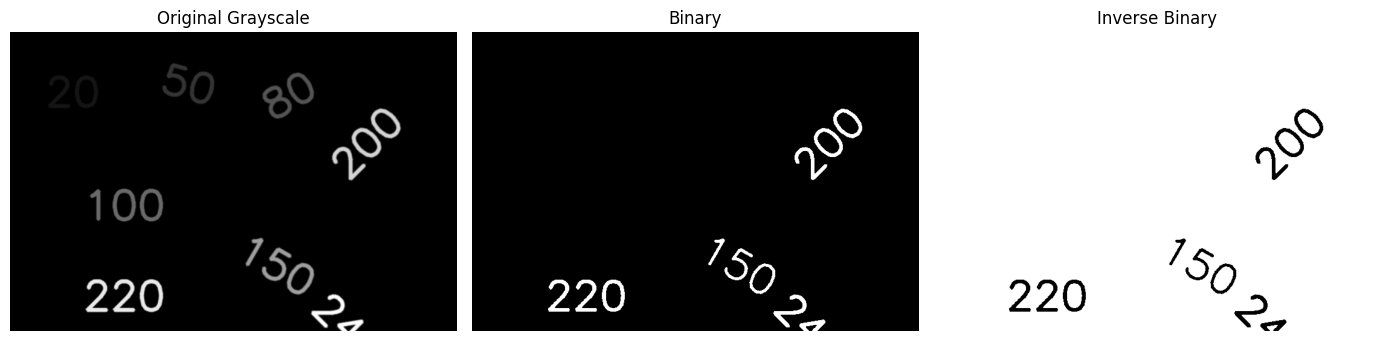

In [4]:
threshold_value = 127

_, binary_inverse = cv2.threshold(
    gray,
    threshold_value,
    255,
    cv2.THRESH_BINARY_INV
)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original Grayscale")

axes[1].imshow(binary, cmap="gray")
axes[1].set_title("Binary")

axes[2].imshow(binary_inverse, cmap="gray")
axes[2].set_title("Inverse Binary")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig('images/2_Thresholding/3.Inverse_Binary_Treshold.jpg')
plt.show()

# Adaptive thresholding

## Adaptive Thresholding: `blockSize` and `C`

```python
cv2.adaptiveThreshold(
    gray, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11, 2
)
```

### 1. `blockSize`
- Defines the size of the local neighborhood used to calculate the threshold.
- Must be an odd integer greater than `1`, such as `3`, `11`, or `21`.
- **Smaller block size:** considers nearby pixels, adapting to small local changes.
- **Larger block size:** considers a wider area, adapting to broader illumination changes.

### 2. `C`
- A constant subtracted from the local mean or weighted mean.
- Formula: `Local threshold = Local mean − C`
- **Increase `C`:** lowers the local threshold; with `THRESH_BINARY`, more pixels tend to become white.
- **Decrease `C`:** raises the local threshold; more pixels tend to become black.

### Important
- `blockSize` controls the neighborhood size.
- `C` shifts the calculated threshold.
- The best values depend on lighting, noise, and text thickness.


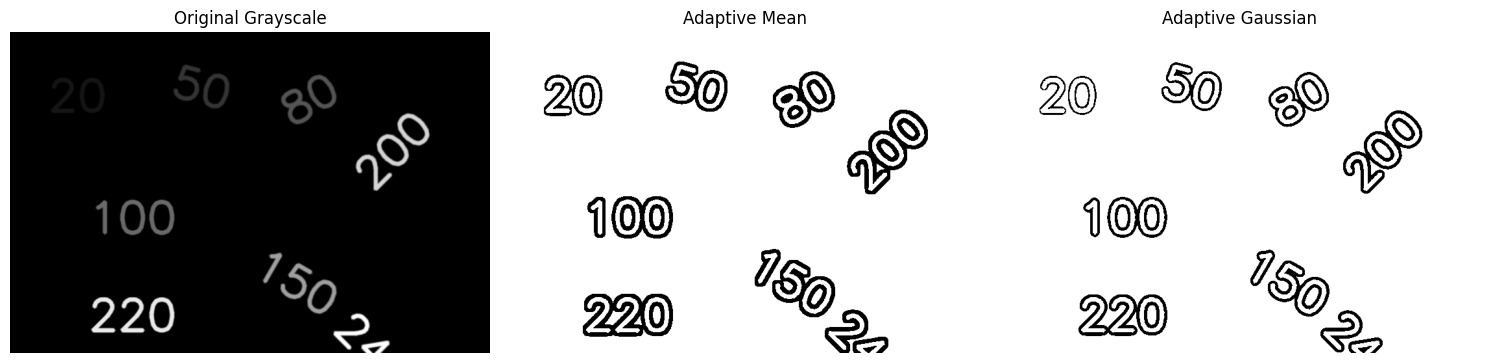

In [5]:
adaptive_mean = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY,
    11, # block size --> 11 * 11
    2   # constant C
)

adaptive_gaussian = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

results = [
    (gray, "Original Grayscale"),
    (adaptive_mean, "Adaptive Mean"),
    (adaptive_gaussian, "Adaptive Gaussian")
]

for ax, (img, title) in zip(axes, results):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.savefig('images/2_Thresholding/4.Adaptive thresholding.jpg')
plt.show()

# Otsu thresholding

Automatically selected Otsu threshold: 82.0


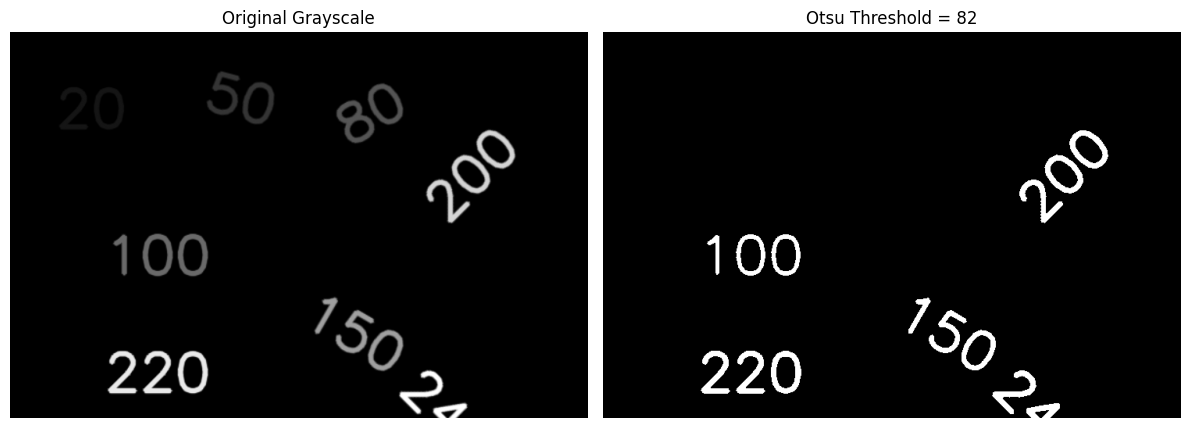

In [6]:
otsu_threshold, otsu_binary = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Automatically selected Otsu threshold:", otsu_threshold)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original Grayscale")

axes[1].imshow(otsu_binary, cmap="gray")
axes[1].set_title(f"Otsu Threshold = {otsu_threshold:.0f}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

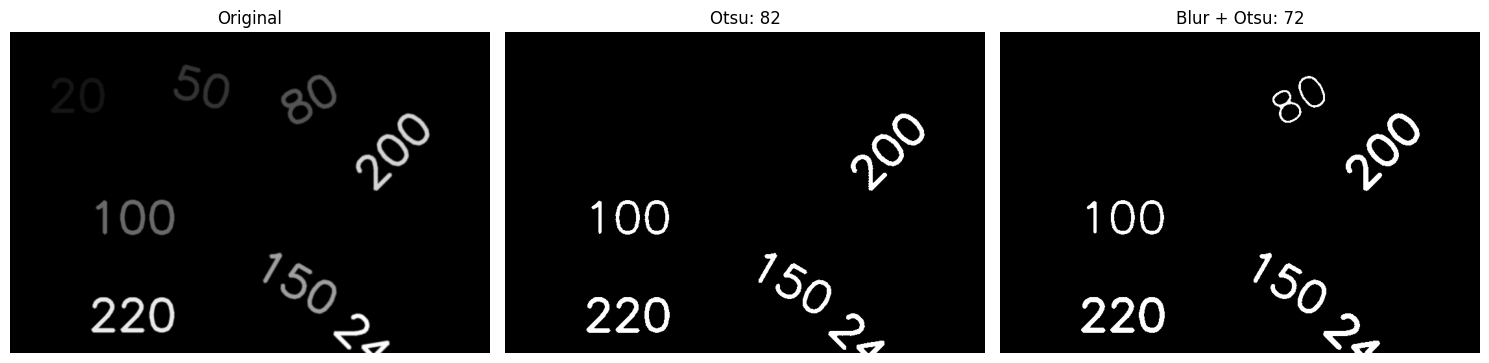

In [7]:
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

otsu_blur_threshold, otsu_blur_binary = cv2.threshold(
    blurred,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original")

axes[1].imshow(otsu_binary, cmap="gray")
axes[1].set_title(f"Otsu: {otsu_threshold:.0f}")

axes[2].imshow(otsu_blur_binary, cmap="gray")
axes[2].set_title(f"Blur + Otsu: {otsu_blur_threshold:.0f}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig('images/2_Thresholding/5.Otsu thresholding.jpg')
plt.show()